# 3 · Preparing an antiferromagnet on a triangular lattice

Rydberg atoms are a natural **quantum simulator** for magnets: the atom states `0` and `1` play the role of spin up and spin down, and the blockade makes neighbouring "down" spins cost energy, an antiferromagnetic interaction.

On a **triangular lattice** this is frustrated: on each triangle, at most two of the three bonds can be satisfied. The material TmMgGaO4 behaves like this, and [Leclerc et al.](https://arxiv.org/abs/2603.20372) studied it with a large Rydberg-atom array. Here we run a small version of that protocol: at zero field the pulse prepares the **antiferromagnetic state** of nine atoms, and a growing longitudinal field then polarises it.

In this notebook you will:

1. map the spin model onto a triangular register,
2. build the two-stage pulse that prepares the antiferromagnet and sets the field,
3. run the field sweep on the GPU, measure magnetisation and correlations, and add your own point,
4. look directly at the measured spin configurations.

**CUDA-Q you will use:** the same `RydbergHamiltonian`, `Schedule` and `evolve_async` as before; what changes is the register and the pulse.

In [1]:
# Copyright 2026 Pasqal
# SPDX-License-Identifier: Apache-2.0
import math
import time
import warnings

warnings.filterwarnings("ignore", message="The CUDA-Q `sample` and `observe`", category=FutureWarning)

import cudaq
from cudaq.dynamics import Schedule
from cudaq.operators import RydbergHamiltonian, ScalarOperator
import matplotlib.pyplot as plt
import numpy as np

from cudaq_pasqal import draw
from cudaq_pasqal.analyze import magnetization, rydberg_density, structure_factor

C6 = 865723.02e-30  # level 60, as in notebooks 1 and 2, in rad m⁶ s⁻¹
cudaq.set_target("pasqal", emulate=True, emulation_rydberg_c6=str(C6))
cudaq.set_random_seed(7)
plt.rcParams.update({"figure.figsize": (7, 3.5), "font.size": 11})

## 1. From the spin model to atoms

The model is an Ising antiferromagnet with a transverse field $\Delta_x$ and a longitudinal field $\Delta_z$, in units of the nearest-neighbour coupling $J_1$:

| Spin model | Atoms |
|---|---|
| Spin $z_i = \pm 1$ | `0` → $+1$, `1` → $-1$ |
| Coupling $J_1$ | $U_1/4$, with $U_1 = C_6/a^6$ at lattice spacing $a$ |
| Transverse field $\Delta_x$ | $\Omega/2$ |
| Longitudinal field $\Delta_z$ | Set by the final detuning |

The experiment fixes $\Delta_x/J_1 = 1.08$. With the drive $\Omega$ chosen, that sets $U_1$, and so the spacing $a = (1.08\, C_6 / 2\Omega)^{1/6}$. Here $C_6$ decides the **geometry**: with another device's $C_6$ the same model needs a lattice scaled by the sixth root of the ratio, and the pulse stays the same.

<details><summary><b>Check yourself:</b> You move to a level-70 device ($C_6$ 6.26 times larger). What spacing does the same model need?</summary>

$a$ grows by $6.26^{1/6} \approx 1.36$: from 5.78 µm to about 7.9 µm. Ω and the detuning sweep stay the same.

</details>

9 atoms, spacing a = 5.78 µm, Δx/J1 = 1.08


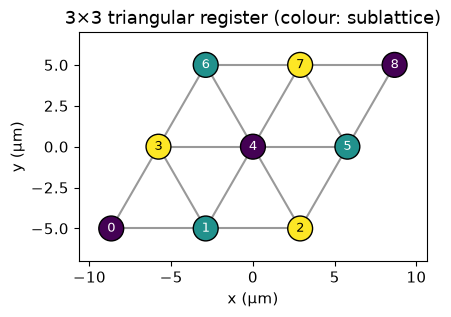

In [2]:
size = 3
omega = 4 * math.pi * 1e6  # peak Rabi frequency, rad/s
spacing = (C6 * 1.08 / (2 * omega)) ** (1 / 6)
lattice = np.array([(i + j / 2, math.sqrt(3) * j / 2) for j in range(size) for i in range(size)])
sites = ((lattice - lattice.mean(axis=0)) * spacing).tolist()

distances = np.linalg.norm(np.subtract(sites, np.array(sites)[:, None]), axis=-1)
np.fill_diagonal(distances, np.inf)
u1 = C6 / spacing**6                                   # nearest-neighbour interaction
du = float((C6 / distances**6).sum(axis=1).mean() / 2)  # Ū: half the interaction an atom feels, averaged
print(f"{len(sites)} atoms, spacing a = {spacing * 1e6:.2f} µm, Δx/J1 = {2 * omega / u1:.2f}")

bonds = [(i, j) for i in range(len(sites)) for j in range(i + 1, len(sites)) if distances[i, j] < 1.1 * spacing]
sublattice = [((i % 3) - (i // 3)) % 3 / 2 for i in range(len(sites))]
draw.register(sites, edges=bonds, values=sublattice, title="3×3 triangular register (colour: sublattice)")
plt.show()

Every small triangle has one atom of each colour: the lattice splits into **three sublattices**. On a triangle, two spins can be anti-aligned but the third cannot be anti-aligned with both: that is the frustration.

## 2. The two-stage pulse

1. **Preparation** (1 µs): with a large negative detuning, ramp up the drive. All atoms start in `0`.
2. **Field sweep** (5 µs): keep the drive, and sweep the detuning to the value that sets $\Delta_z$: $\Delta_f = \bar U - \Delta_z U_1/2$, where $\bar U = \tfrac12\langle\sum_j U_{ij}\rangle$ is half the interaction an atom feels from all the others, averaged over atoms (the ½ comes from writing $n = (1 - z)/2$). Note the direction: a **stronger** field means a **smaller** final detuning. At large $\Delta_z$ the detuning ends negative and favours every atom in `0`, spin up.

Each sweep point is the same pulse with a different final detuning, so one function builds the program for a given $\Delta_z/J_1$:

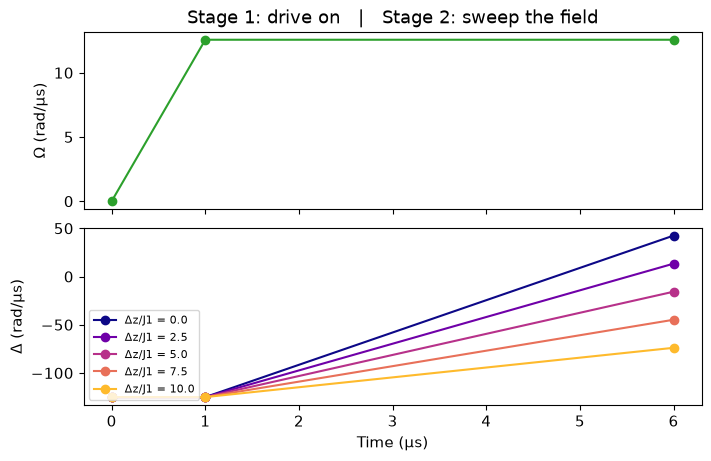

In [3]:
times = [0.0, 1e-6, 6e-6]
amplitude = [0.0, omega, omega]


def field_sweep(dz_j1):
    """Return the Hamiltonian and detuning samples for one longitudinal field Δz/J1."""
    detuning = [-125e6, -125e6, du - dz_j1 * u1 / 2]
    hamiltonian = RydbergHamiltonian(
        atom_sites=sites,
        amplitude=ScalarOperator(lambda t: float(np.interp(t.real, times, amplitude))),
        phase=ScalarOperator.const(0.0),
        delta_global=ScalarOperator(lambda t: float(np.interp(t.real, times, detuning))),
    )
    return hamiltonian, detuning


fields = np.linspace(0, 10, 5)  # Δz/J1
fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(7, 4.5), layout="constrained")
top.plot(np.array(times) * 1e6, np.array(amplitude) / 1e6, "o-", color="tab:green")
for dz, color in zip(fields, plt.cm.plasma(np.linspace(0, 0.85, len(fields)))):
    bottom.plot(np.array(times) * 1e6, np.array(field_sweep(dz)[1]) / 1e6, "o-", color=color, label=f"Δz/J1 = {dz:.1f}")
top.set(ylabel="Ω (rad/µs)", title="Stage 1: drive on   |   Stage 2: sweep the field")
bottom.set(xlabel="Time (µs)", ylabel="Δ (rad/µs)")
bottom.legend(fontsize=8, loc="lower left")
plt.show()

## 3. Run the field sweep

Nine atoms means $2^9 = 512$ amplitudes. We launch the five points with `evolve_async` and collect them; this takes a few minutes on a laptop-class GPU.

In [4]:
# Predict: the magnetisation M_z at zero field and at the strongest field, Δz/J1 = 10? Each from -1 to 1, or None.
predicted_mz = {0.0: None, 10.0: None}

5 points in 182 s


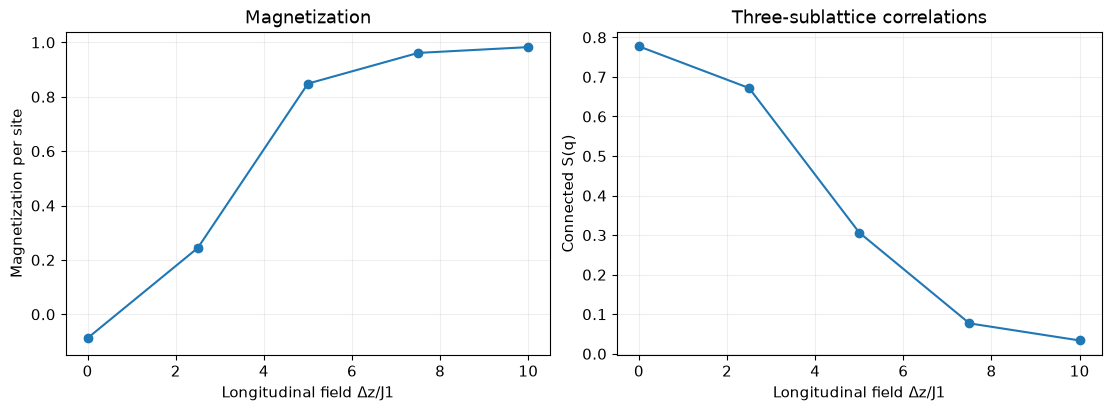

Δz/J1 = 0: you predicted M_z = None, measured -0.09
Δz/J1 = 10: you predicted M_z = None, measured 0.98


In [5]:
start = time.monotonic()
futures = [cudaq.evolve_async(field_sweep(dz)[0], schedule=Schedule(times, ["t"]), shots_count=500) for dz in fields]
sweep = [dict(f.get().items()) for f in futures]
print(f"{len(fields)} points in {time.monotonic() - start:.0f} s")

mz, mz_err = np.array([magnetization(c) for c in sweep]).T
sq = [structure_factor(c, sites, spacing) for c in sweep]
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
left.errorbar(fields, mz, yerr=mz_err, marker="o", capsize=3)
left.set(xlabel="Longitudinal field Δz/J1", ylabel="Magnetization per site", title="Magnetization")
right.plot(fields, sq, "o-")
right.set(xlabel="Longitudinal field Δz/J1", ylabel="Connected S(q)", title="Three-sublattice correlations")
for ax in (left, right):
    ax.grid(alpha=0.2)
plt.show()
for dz, guess in predicted_mz.items():
    print(f"Δz/J1 = {dz:g}: you predicted M_z = {guess}, measured {mz[list(fields).index(dz)]:.2f}")

Two observables, both computed from the measured bitstrings with $z = 1 - 2n$:

- **Magnetisation** $M_z = \frac{1}{N}\sum_i \langle z_i\rangle$: $+1$ when every atom is in `0`.
- **Connected structure factor** at the three-sublattice wavevector $q$,
  $S(q) = \frac{1}{N}\sum_{ij} e^{iq\cdot(r_i - r_j)}\left(\langle z_i z_j\rangle - \langle z_i\rangle\langle z_j\rangle\right)$, which is large when spins fluctuate *together* with a three-sublattice pattern.

At zero field we prepared an **antiferromagnet**: $M_z \approx 0$, and neighbouring spins anti-align as much as the triangles allow, which shows up as a large $S(q)$. A strong field $\Delta_z$ polarises all spins ($M_z \to 1$) and kills the correlations. In between, [Leclerc et al.](https://arxiv.org/abs/2603.20372) find a **plateau at $M_z = 1/3$**, one spin in three down on a single sublattice. Seeing it takes larger arrays and a finer sweep than five points on nine atoms.

### Your table's point

Five points leave big gaps. Each table picks one field between the points above, runs it (about 40 s) and calls out $M_z$ and $S(q)$.

In [6]:
my_field = 3.75  # Δz/J1, your table's choice between 0 and 10
my_counts = dict(cudaq.evolve(field_sweep(my_field)[0], schedule=Schedule(times, ["t"]), shots_count=500).items())
my_mz = magnetization(my_counts)[0]
print(f"Δz/J1 = {my_field}: M_z = {my_mz:.2f}, S(q) = {structure_factor(my_counts, sites, spacing):.2f}")

Δz/J1 = 3.75: M_z = 0.62, S(q) = 0.71


The presenter types what the room calls out into `room`, as `{Δz/J1: M_z}`, and reruns this cell:

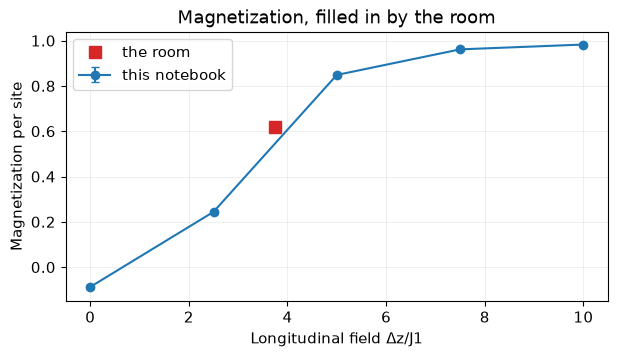

In [7]:
room = {my_field: my_mz}  # e.g. {1.25: 0.05, 3.75: 0.6, ...}
plt.errorbar(fields, mz, yerr=mz_err, marker="o", capsize=3, label="this notebook")
plt.plot(*zip(*sorted(room.items())), "s", ms=8, color="tab:red", label="the room")
plt.xlabel("Longitudinal field Δz/J1")
plt.ylabel("Magnetization per site")
plt.title("Magnetization, filled in by the room")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


<details><summary><b>Check yourself:</b> Which bitstring gives $M_z = +1$, and which $M_z = -1$?</summary>

`000000000` gives $+1$, every spin up. $-1$ would be all atoms in `1`, which the blockade forbids for neighbours: you never see it here.

</details>

## 4. Look at the configurations

The bitstrings are snapshots of the spins. Below, the most frequent ones at zero and strong field, with excited atoms in yellow:

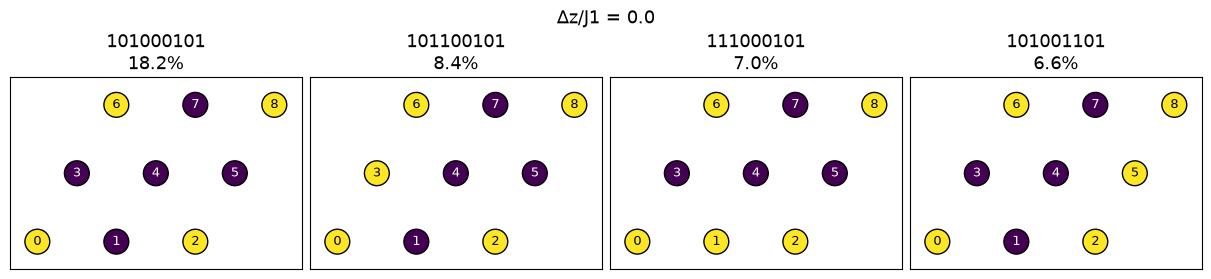

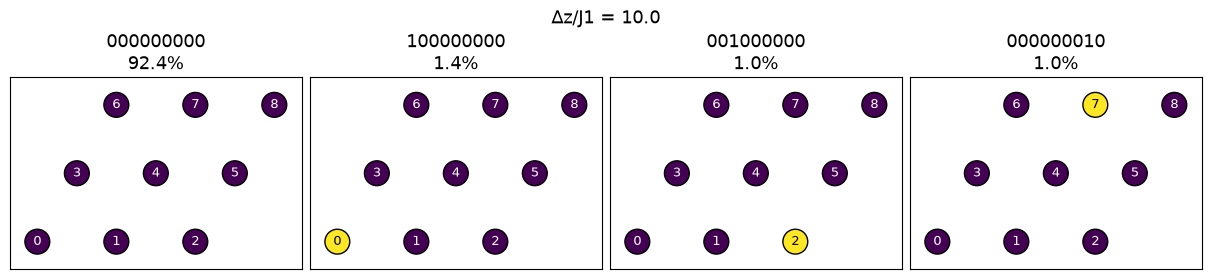

In [8]:
for index in (0, -1):
    draw.snapshots(sites, sweep[index], title=f"Δz/J1 = {fields[index]:.1f}")
    plt.show()

At zero field about half the atoms are excited and they avoid excited neighbours: the antiferromagnetic state. The corners, which have the fewest neighbours, are excited most often: in such a small open register the boundary shapes the pattern. At strong field almost every shot is all `0`. The average picture across the sweep:

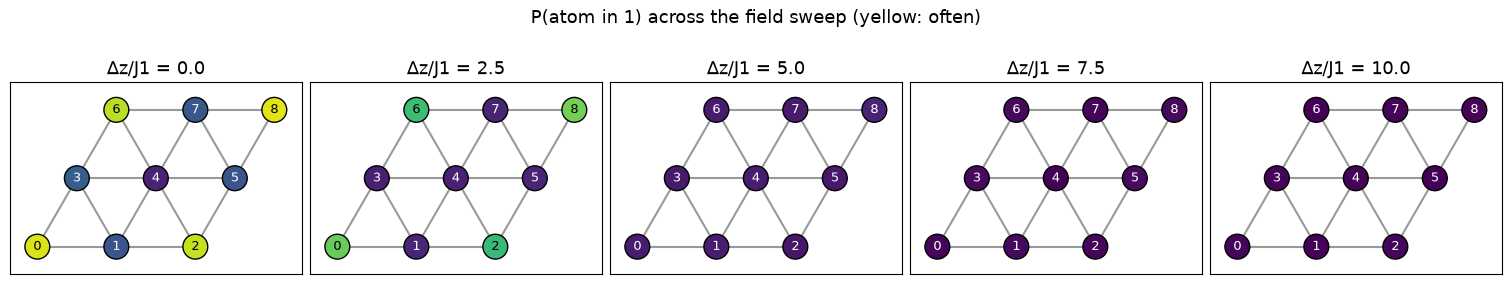

In [9]:
fig, axes = plt.subplots(1, len(sweep), figsize=(15, 3.2), layout="constrained")
for ax, dz, counts in zip(axes, fields, sweep):
    draw.register(sites, edges=bonds, values=rydberg_density(counts), ax=ax, title=f"Δz/J1 = {dz:.1f}")
    ax.set(xlabel="", ylabel="", xticks=[], yticks=[])
fig.suptitle("P(atom in 1) across the field sweep (yellow: often)")
plt.show()

## Key points

- Rydberg atoms simulate an **antiferromagnet**: blockade is the interaction, the drive a transverse field, the detuning a longitudinal one. The same adiabatic idea as the MIS anneal prepares its low-energy state.
- The model fixes ratios; $C_6$ then fixes the lattice spacing.
- A triangular register is **frustrated** and splits into three sublattices.
- Magnetisation and the structure factor come directly from the measured bitstrings, which are snapshots of the spins.
- Nine atoms show the protocol and strong **finite-size effects**; the paper's conclusions need much larger arrays, the regime of real QPUs. State-vector emulation doubles in cost with every atom.

<div class="alert alert-success">

**To go further**

- Use 9 field values instead of 5. Where does $S(q)$ drop? Is there a hint of a plateau near $M_z = 1/3$?
- Set `size = 4` (16 atoms, 65 536 amplitudes) and time one point. How does the cost grow from 9 atoms?
- The [Pulser tutorials](https://docs.pasqal.com/pulser/) cover adiabatic preparation of antiferromagnetic states in more depth.
- For the full material application, Pasqal's [SC26 OpenQSE demonstration](https://github.com/pasqal-io/sc26-openqse-demo) runs the TmMgGaO4 field sweep, written in Pulser, as Slurm jobs on a Pasqal device and looks for the 1/3 magnetisation plateau of the paper.

</div>